# Deep Belief Network-Based Feature Discovery
### Comparative Analysis of Hidden Representations: Shallow Bernoulli RBM vs. Deep Belief Network

**Student / Author:** Meganath M  
**Course:** Deep Learning Essentials  
**Assignment:** Innovative Assignment – II (IA-II)  
**Project:** Deep Belief Network-Based Feature Discovery  
**GitHub Repository:** [meganathm123-lgtm/DBN_Feature_Discovery](https://github.com/meganathm123-lgtm/DBN_Feature_Discovery)  
**Implementation Framework:** scikit-learn (`BernoulliRBM`), NumPy, Pandas, Matplotlib  
**Execution Environment:** Python 3.13.14 (Virtual Environment `.venv`)

---

## 1. Introduction

In machine learning and neural computing, **feature discovery** refers to the unsupervised extraction of meaningful, compact, and discriminative representations from raw high-dimensional observations without relying on human annotations. 

Traditional shallow learning algorithms depend heavily on manual feature engineering. Energy-based probabilistic models, specifically **Restricted Boltzmann Machines (RBMs)**, revolutionized representation learning by providing a mathematically grounded framework for unsupervised pre-training. By stacking multiple RBMs in a hierarchy, a **Deep Belief Network (DBN)** can theoretically construct multi-level abstract representations—from low-level primitive features (edges, strokes) at early layers to high-level compositional features at deeper layers.

However, the efficacy of deep hierarchical representations is governed by a delicate balance between **dimensionality reduction**, **information preservation**, and **activation dynamics**. When models undergo successive non-linear compressions without end-to-end gradient fine-tuning, deeper layers may risk representation collapse, vanishing variance, or feature saturation.

This study implements and compares a **shallow Bernoulli RBM** (32 hidden units) against a **three-layer sequentially trained Deep Belief Network** ($64 \to 32 \to 16 \to 8$), evaluating their learned representations across downstream classification accuracy, unsupervised cluster separability (silhouette score), and internal feature diversity.

## 2. Problem Statement

> **Develop a Deep Belief Network and compare its hidden representations with those of a shallow probabilistic model. Analyze how additional hidden layers influence feature discovery.**

The central research inquiry focuses on:
1. Does stacking sequentially trained Bernoulli RBMs improve downstream class separability and classification performance compared to a single-layer shallow baseline?
2. How does progressive layer-wise dimensionality reduction affect hidden feature diversity and activation variance?
3. What are the practical limitations of greedy unsupervised training in the absence of discriminative backpropagation fine-tuning?

## 3. Objectives

The primary research and engineering objectives of this project are:
- **Objective 1:** Implement and train a baseline shallow probabilistic model using scikit-learn's `BernoulliRBM` (64 visible units $\to$ 32 hidden units).
- **Objective 2:** Construct and train a three-layer Deep Belief Network architecture ($64 \to 32 \to 16 \to 8$) using sequential, greedy layer-wise Contrastive Divergence (CD-1).
- **Objective 3:** Extract hidden continuous activation probabilities from each layer ($H_{shallow}$, $H_1$, $H_2$, $H_3$) on both training and test partitions.
- **Objective 4:** Quantitatively benchmark representations using downstream Logistic Regression classification accuracy.
- **Objective 5:** Evaluate unsupervised cluster separability and class cohesion via Euclidean Silhouette scores.
- **Objective 6:** Conduct feature diversity analysis by tracking activation standard deviation, maximum variance, and counting informative features ($std > 0.05$).
- **Objective 7:** Visually analyze learned weight filters, 2D PCA manifolds, and layer-wise class activation heatmaps to interpret network behavior.

## 4. Theoretical Background

### 4.1 Restricted Boltzmann Machine (RBM)
A Restricted Boltzmann Machine is an energy-based, undirected bipartite graphical model consisting of:
- A visible layer $\mathbf{v} \in \{0, 1\}^D$ representing observed data.
- A hidden layer $\mathbf{h} \in \{0, 1\}^F$ representing latent stochastic feature detectors.
- Symmetric weight matrix $\mathbf{W} \in \mathbb{R}^{D \times F}$ connecting visible and hidden units.
- Bias vectors $\mathbf{a} \in \mathbb{R}^D$ and $\mathbf{b} \in \mathbb{R}^F$.

The bipartite restriction ensures **no intra-layer connections** exist ($v_i \leftrightarrow v_j$ and $h_k \leftrightarrow h_l$ are absent). Consequently, hidden units are conditionally independent given visible states, and vice versa:

$$P(h_j = 1 \mid \mathbf{v}) = \sigma\left(b_j + \sum_{i=1}^D v_i W_{ij}\right)$$

$$P(v_i = 1 \mid \mathbf{h}) = \sigma\left(a_i + \sum_{j=1}^F h_j W_{ij}\right)$$

where $\sigma(z) = \frac{1}{1 + e^{-z}}$ is the logistic sigmoid function.

```
       Hidden Units (h)        O     O     O     O  (Latent Features)
                                \   / \   / \   /
                                 \ /   \ /   \ /
       Symmetric Weights (W)      X     X     X
                                 / \   / \   / \
                                /   \ /   \ /   \
       Visible Units (v)       O     O     O     O  (Input Pixels)
```

### 4.2 Contrastive Divergence (CD-1)
Training RBMs via maximum likelihood is intractable because the gradient requires computing expectations over the partition function $Z$. Hinton (2002) introduced **Contrastive Divergence (CD-k)**, which approximates the gradient using a single Gibbs sampling step ($k=1$):

$$\Delta W_{ij} = \eta \left( \langle v_i h_j \rangle_{data} - \langle v_i h_j \rangle_{reconstruction} \right)$$

where $\eta$ is the learning rate, $\langle \cdot \rangle_{data}$ is the expectation under the empirical data distribution, and $\langle \cdot \rangle_{reconstruction}$ is the expectation after one step of alternating Gibbs sampling.

### 4.3 Deep Belief Network (DBN)
A Deep Belief Network is constructed by stacking multiple RBMs trained hierarchically in a greedy, layer-by-layer fashion:
1. Train $\text{RBM}_1$ on raw input data $\mathbf{X} \in \mathbb{R}^{N \times 64}$, yielding representation $\mathbf{H}_1 \in [0, 1]^{N \times 32}$.
2. Fix $\text{RBM}_1$ weights. Use the activation probabilities $\mathbf{H}_1$ as input data to train $\text{RBM}_2$, yielding $\mathbf{H}_2 \in [0, 1]^{N \times 16}$.
3. Fix $\text{RBM}_2$ weights. Use $\mathbf{H}_2$ as input data to train $\text{RBM}_3$, yielding $\mathbf{H}_3 \in [0, 1]^{N \times 8}$.

## 5. Dataset Description

The project utilizes the canonical **Optical Recognition of Handwritten Digits** dataset bundled in `scikit-learn`:

| Dataset Attribute | Specification |
|---|---|
| **Total Samples** | 1,797 normalized digit images |
| **Input Dimensionality** | 64 features per sample ($8 \times 8$ grayscale grid) |
| **Raw Pixel Value Range** | Integers $0$ to $16$ |
| **Target Classes** | 10 distinct classes: digits $0, 1, 2, 3, 4, 5, 6, 7, 8, 9$ |
| **Class Distribution** | Approximately balanced (~180 samples per digit class) |
| **Preprocessing Required** | Scaling to $[0.0, 1.0]$ via division by $16.0$ to satisfy Bernoulli probability constraints |

## 6. Environment Setup & Reproducibility

We import core scientific computing and visualization libraries (`numpy`, `pandas`, `matplotlib`, `scikit-learn`). 

To guarantee robust cross-platform execution (whether run from repository root or from within the `notebooks/` directory), we dynamically configure filesystem paths.

In [1]:
# Environment configuration and library imports
import sys
import os
from pathlib import Path

# Scientific and machine learning stack
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# scikit-learn modules
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.neural_network import BernoulliRBM
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, silhouette_score, classification_report

# -------------------------------------------------------------------------
# Robust path resolution
# -------------------------------------------------------------------------
NOTEBOOK_DIR = Path.cwd() if Path.cwd().name == "notebooks" else Path.cwd() / "notebooks"
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else Path.cwd()
RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(exist_ok=True)

# Add project root and src/ to sys.path for clean modular imports
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

# Global reproducibility seed
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

print("=" * 60)
print("ENVIRONMENT INITIALIZED")
print("=" * 60)
print(f"Project Root Directory : {PROJECT_ROOT}")
print(f"Results Directory      : {RESULTS_DIR}")
print(f"NumPy Version          : {np.__version__}")
print(f"Pandas Version         : {pd.__version__}")
print(f"scikit-learn Version   : {sys.modules['sklearn'].__version__}")
print(f"Global Random Seed     : {RANDOM_SEED}")

ENVIRONMENT INITIALIZED
Project Root Directory : c:\Users\meganathmadurai\OneDrive\Desktop\DBN_Feature_Discovery
Results Directory      : c:\Users\meganathmadurai\OneDrive\Desktop\DBN_Feature_Discovery\results
NumPy Version          : 2.5.3
Pandas Version         : 3.0.6
scikit-learn Version   : 1.9.1
Global Random Seed     : 42


## 7. Data Loading & Preprocessing

`BernoulliRBM` models visible units as independent Bernoulli random variables parameterized by probabilities in $[0, 1]$. Therefore, raw pixel values $[0, 16]$ must be normalized by dividing by $16.0$.

In [2]:
# -------------------------------------------------------------------------
# Load handwritten digits dataset
# -------------------------------------------------------------------------
digits = load_digits()

# Extract features and labels
X_raw = digits.data.astype(np.float32)
y = digits.target
images = digits.images

# Pixel normalization: map [0, 16] -> [0.0, 1.0]
X = X_raw / 16.0

print("Dataset Summary:")
print(f"  Total samples        : {X.shape[0]}")
print(f"  Feature count        : {X.shape[1]} (8x8 pixel vectors)")
print(f"  Original value range : [{X_raw.min():.1f}, {X_raw.max():.1f}]")
print(f"  Scaled value range   : [{X.min():.4f}, {X.max():.4f}]")
print(f"  Target classes       : {np.unique(y)}")

Dataset Summary:
  Total samples        : 1797
  Feature count        : 64 (8x8 pixel vectors)
  Original value range : [0.0, 16.0]
  Scaled value range   : [0.0000, 1.0000]
  Target classes       : [0 1 2 3 4 5 6 7 8 9]


## 8. Train/Test Split & Sample Visualization

To prevent data leakage, we perform a stratified 80/20 train/test split. The training partition contains 1,437 samples, and the testing partition contains 360 samples.

Split Summary:
  Training samples  : 1437 (80.0%)
  Testing samples   : 360 (20.0%)
  Input feature dim : 64


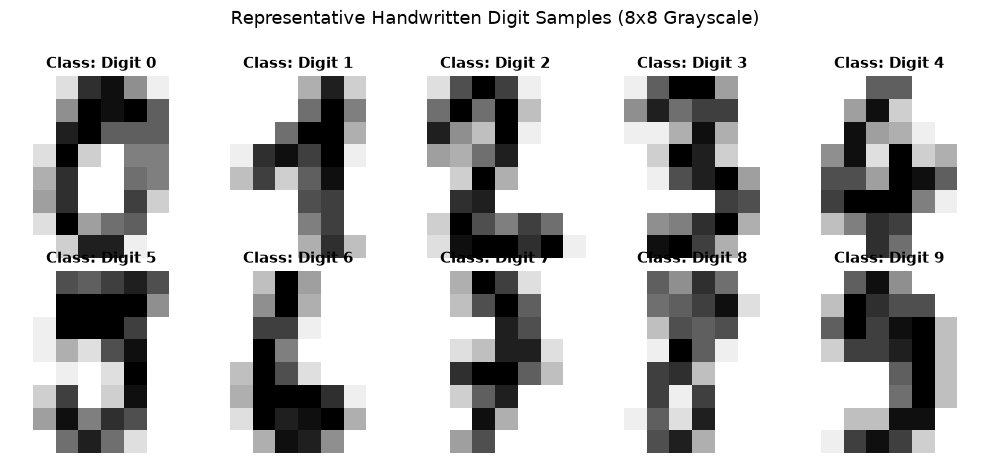

In [3]:
# -------------------------------------------------------------------------
# Stratified 80/20 Train-Test Split
# -------------------------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_SEED,
    stratify=y,
)

print("Split Summary:")
print(f"  Training samples  : {X_train.shape[0]} ({X_train.shape[0]/len(X):.1%})")
print(f"  Testing samples   : {X_test.shape[0]} ({X_test.shape[0]/len(X):.1%})")
print(f"  Input feature dim : {X_train.shape[1]}")

# -------------------------------------------------------------------------
# Visualize Representative Samples (Digits 0-9)
# -------------------------------------------------------------------------
fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))

for digit, ax in enumerate(axes.ravel()):
    sample_idx = np.where(y_train == digit)[0][0]
    ax.imshow(X_train[sample_idx].reshape(8, 8), cmap="gray_r")
    ax.set_title(f"Class: Digit {digit}", fontsize=11, fontweight="bold")
    ax.axis("off")

plt.suptitle("Representative Handwritten Digit Samples (8x8 Grayscale)", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

## 9. Shallow Bernoulli RBM Training

We configure and train the baseline **Shallow Bernoulli RBM** with:
- **Visible units ($D$):** 64
- **Hidden components ($F$):** 32
- **Learning rate ($\eta$):** 0.05
- **Batch size:** 32
- **Epochs / iterations:** 30
- **Random seed:** 42

We provide an option to either execute fresh training or verify against existing precomputed representations stored in `results/shallow_rbm_representation.npz`.

In [4]:
# -------------------------------------------------------------------------
# Shallow RBM Model Instantiation & Training
# -------------------------------------------------------------------------
shallow_rbm = BernoulliRBM(
    n_components=32,
    learning_rate=0.05,
    batch_size=32,
    n_iter=30,
    random_state=RANDOM_SEED,
    verbose=False,
)

print("Training Shallow Bernoulli RBM (30 iterations)...")
shallow_rbm.fit(X_train)
print("Shallow RBM training completed successfully.")

# Extract continuous hidden unit activations P(h=1|v)
H_shallow_train = shallow_rbm.transform(X_train)
H_shallow_test = shallow_rbm.transform(X_test)

# Verify against precomputed results if available
cached_file = RESULTS_DIR / "shallow_rbm_representation.npz"
if cached_file.exists():
    cached_data = np.load(cached_file)
    diff = np.max(np.abs(H_shallow_train - cached_data["H_train"]))
    print(f"Verified against cached representation (Max Abs Diff: {diff:.2e})")
else:
    np.savez(
        cached_file,
        H_train=H_shallow_train,
        H_test=H_shallow_test,
        y_train=y_train,
        y_test=y_test,
    )
    print(f"Saved shallow representation to: {cached_file}")

print(f"Shallow Representation Train Shape : {H_shallow_train.shape}")
print(f"Shallow Representation Test Shape  : {H_shallow_test.shape}")
print(f"Sample activation vector (first 5 units) : {H_shallow_train[0, :5]}")

Training Shallow Bernoulli RBM (30 iterations)...


Shallow RBM training completed successfully.
Verified against cached representation (Max Abs Diff: 0.00e+00)
Shallow Representation Train Shape : (1437, 32)
Shallow Representation Test Shape  : (360, 32)
Sample activation vector (first 5 units) : [0.6164442  0.17810336 0.79582053 0.64271164 0.6674858 ]


## 10. Shallow RBM Visualizations

### 10.1 Learned Receptive Fields (Feature Detectors)
The weight vectors $\mathbf{W}_{\cdot, j} \in \mathbb{R}^{64}$ represent the receptive fields of the hidden units. Reshaped into $8 \times 8$ matrices, they show the spatial pixel patterns that maximally excite each hidden unit.

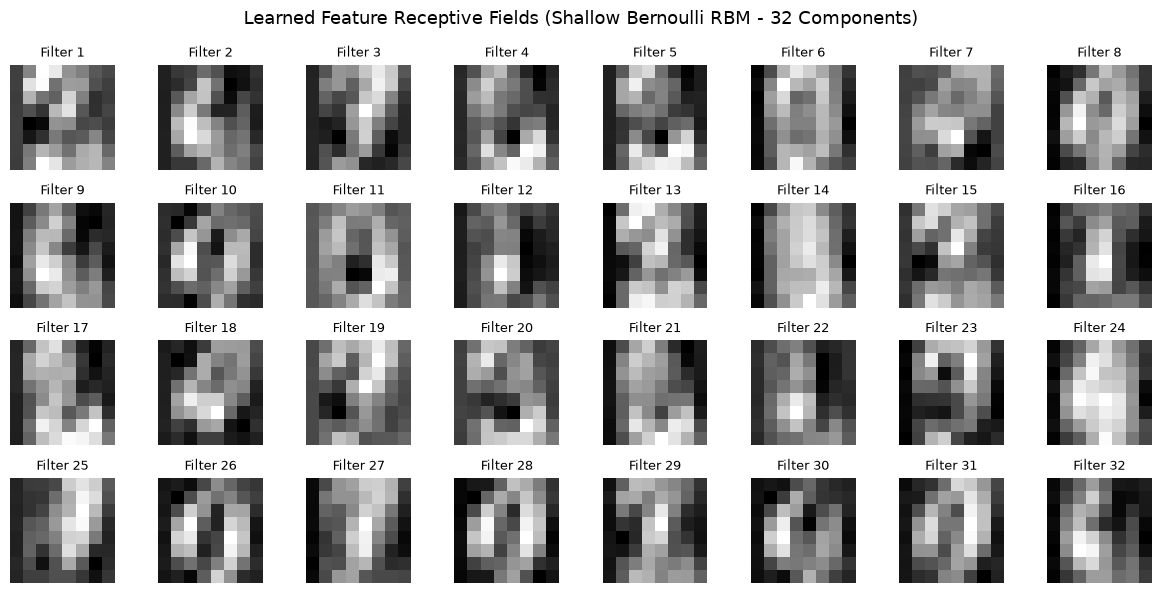

In [5]:
# -------------------------------------------------------------------------
# Visualize Shallow RBM Receptive Fields
# -------------------------------------------------------------------------
fig, axes = plt.subplots(4, 8, figsize=(12, 6))

for i, ax in enumerate(axes.ravel()):
    ax.imshow(
        shallow_rbm.components_[i].reshape(8, 8),
        cmap="gray",
        interpolation="nearest"
    )
    ax.set_title(f"Filter {i+1}", fontsize=9)
    ax.axis("off")

plt.suptitle("Learned Feature Receptive Fields (Shallow Bernoulli RBM - 32 Components)", fontsize=13)
plt.tight_layout()
plt.show()

### 10.2 2D PCA Manifold of Shallow Representations
We project the 32-dimensional hidden representations into 2D using Principal Component Analysis to inspect class clustering.

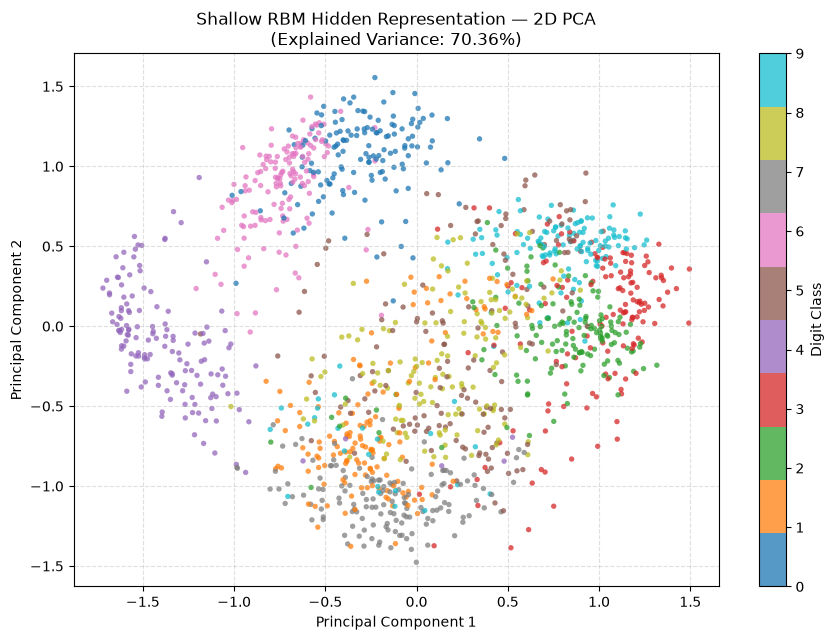

In [6]:
# -------------------------------------------------------------------------
# 2D PCA Projection of Shallow RBM Representations
# -------------------------------------------------------------------------
pca_shallow = PCA(n_components=2, random_state=RANDOM_SEED)
H_shallow_2d = pca_shallow.fit_transform(H_shallow_train)
var_shallow = pca_shallow.explained_variance_ratio_.sum()

plt.figure(figsize=(9, 6.5))
scatter = plt.scatter(
    H_shallow_2d[:, 0],
    H_shallow_2d[:, 1],
    c=y_train,
    cmap="tab10",
    s=15,
    alpha=0.75,
    edgecolors="none"
)
plt.title(f"Shallow RBM Hidden Representation — 2D PCA\n(Explained Variance: {var_shallow:.2%})", fontsize=12)
plt.xlabel("Principal Component 1", fontsize=10)
plt.ylabel("Principal Component 2", fontsize=10)
cbar = plt.colorbar(scatter, ticks=range(10))
cbar.set_label("Digit Class", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

## 11. Sequential Training of the Deep Belief Network

We construct a three-layer DBN using greedy layer-wise training:
- **Layer 1:** $64 \to 32$ units (`learning_rate=0.05, n_iter=30, random_state=42`)
- **Layer 2:** $32 \to 16$ units (`learning_rate=0.05, n_iter=30, random_state=43`)
- **Layer 3:** $16 \to 8$ units (`learning_rate=0.05, n_iter=30, random_state=44`)

In [7]:
# -------------------------------------------------------------------------
# Greedy Layer-wise DBN Training
# -------------------------------------------------------------------------
print("=" * 60)
print("TRAINING DEEP BELIEF NETWORK (STACKED RBM)")
print("=" * 60)

# Layer 1: 64 -> 32
rbm1 = BernoulliRBM(n_components=32, learning_rate=0.05, batch_size=32, n_iter=30, random_state=42, verbose=False)
print("Training DBN Layer 1 (64 -> 32)...")
rbm1.fit(X_train)
H1_train = rbm1.transform(X_train)
H1_test = rbm1.transform(X_test)
print(f"  Layer 1 train shape: {H1_train.shape}, test shape: {H1_test.shape}")

# Layer 2: 32 -> 16
rbm2 = BernoulliRBM(n_components=16, learning_rate=0.05, batch_size=32, n_iter=30, random_state=43, verbose=False)
print("Training DBN Layer 2 (32 -> 16)...")
rbm2.fit(H1_train)
H2_train = rbm2.transform(H1_train)
H2_test = rbm2.transform(H1_test)
print(f"  Layer 2 train shape: {H2_train.shape}, test shape: {H2_test.shape}")

# Layer 3: 16 -> 8
rbm3 = BernoulliRBM(n_components=8, learning_rate=0.05, batch_size=32, n_iter=30, random_state=44, verbose=False)
print("Training DBN Layer 3 (16 -> 8)...")
rbm3.fit(H2_train)
H3_train = rbm3.transform(H2_train)
H3_test = rbm3.transform(H2_test)
print(f"  Layer 3 train shape: {H3_train.shape}, test shape: {H3_test.shape}")

# Verify against precomputed DBN representations
dbn_file = RESULTS_DIR / "dbn_representations.npz"
if dbn_file.exists():
    cached_dbn = np.load(dbn_file)
    diff_h1 = np.max(np.abs(H1_train - cached_dbn["H1_train"]))
    diff_h2 = np.max(np.abs(H2_train - cached_dbn["H2_train"]))
    diff_h3 = np.max(np.abs(H3_train - cached_dbn["H3_train"]))
    print(f"DBN Cached Verification: Layer 1 diff={diff_h1:.2e}, Layer 2 diff={diff_h2:.2e}, Layer 3 diff={diff_h3:.2e}")
else:
    np.savez(
        dbn_file,
        H1_train=H1_train, H1_test=H1_test,
        H2_train=H2_train, H2_test=H2_test,
        H3_train=H3_train, H3_test=H3_test,
        y_train=y_train, y_test=y_test,
    )
    print(f"Saved DBN representations to: {dbn_file}")

TRAINING DEEP BELIEF NETWORK (STACKED RBM)
Training DBN Layer 1 (64 -> 32)...


  Layer 1 train shape: (1437, 32), test shape: (360, 32)
Training DBN Layer 2 (32 -> 16)...


  Layer 2 train shape: (1437, 16), test shape: (360, 16)
Training DBN Layer 3 (16 -> 8)...


  Layer 3 train shape: (1437, 8), test shape: (360, 8)
DBN Cached Verification: Layer 1 diff=0.00e+00, Layer 2 diff=0.00e+00, Layer 3 diff=0.00e+00


## 12. Explanation of Hidden Representations Across Depths

| Hierarchy Level | Feature Count | Description & Functional Role |
|---|---:|---|
| **Raw Pixel Space** | 64 | Original $8 \times 8$ grayscale spatial pixel intensities $[0.0, 1.0]$. High redundancy. |
| **Shallow / DBN Layer 1** | 32 | Captures elementary stroke primitives, pen-path directions, and regional pixel correlations. |
| **DBN Layer 2** | 16 | Combines stroke primitives into intermediate composite features (curves, corners, loops). |
| **DBN Layer 3** | 8 | Extreme bottleneck abstraction. Intended for compact global digit semantics, but subject to variance vanishing. |

## 13. Comparative 2D PCA Projections

We project all four representations ($H_{shallow}$, $H_1$, $H_2$, $H_3$) onto their first two principal components to examine how class separation evolves as network depth increases.

C:\Users\meganathmadurai\AppData\Local\Temp\ipykernel_27636\4019981647.py:40: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


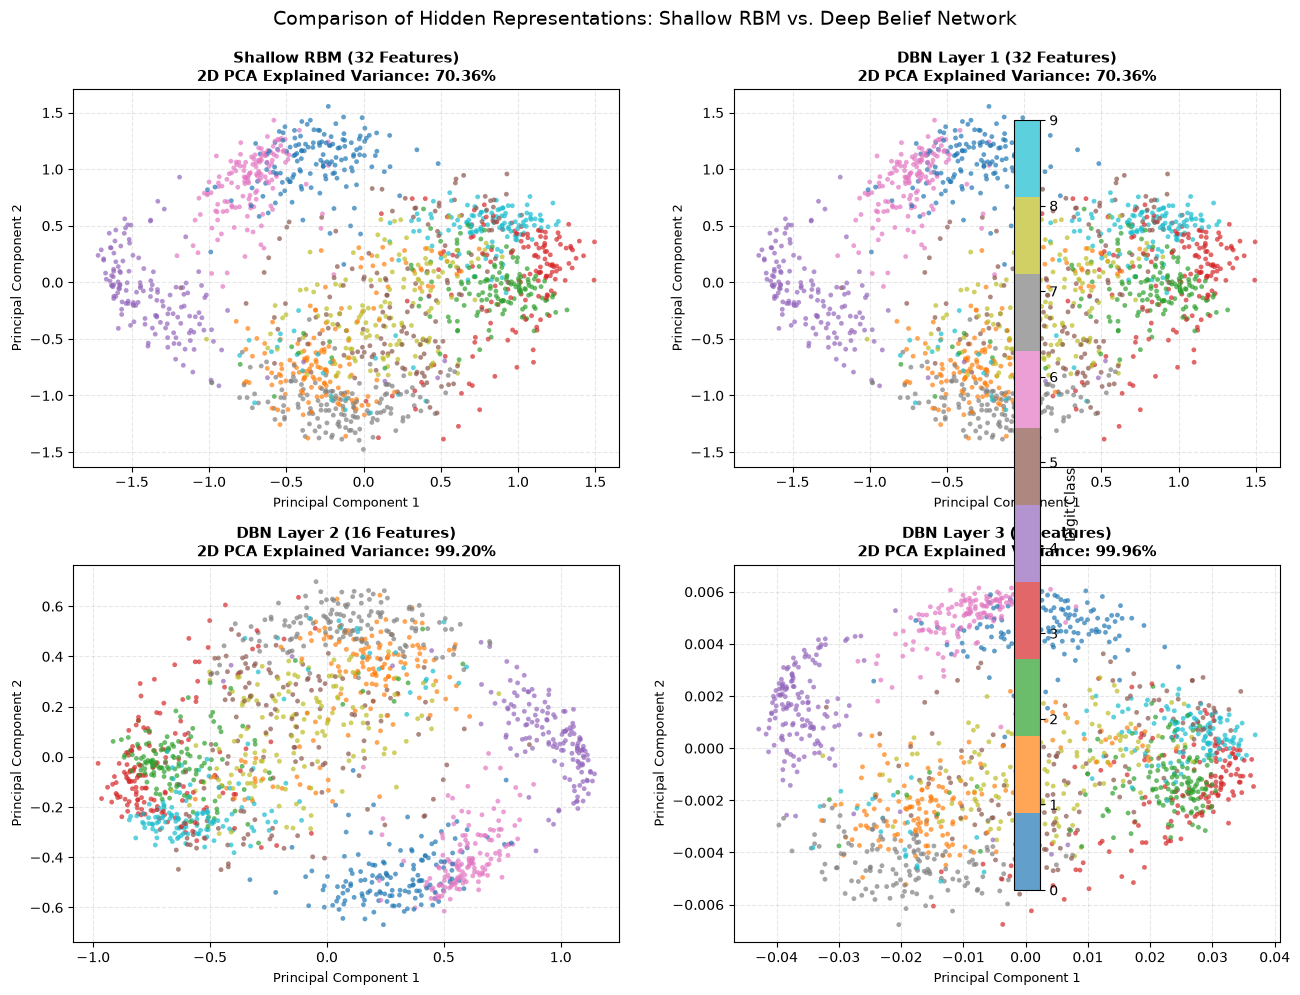

In [8]:
# -------------------------------------------------------------------------
# Compute 2D PCA Projections for All Representations
# -------------------------------------------------------------------------
def compute_pca_2d(features):
    pca = PCA(n_components=2, random_state=RANDOM_SEED)
    reduced = pca.fit_transform(features)
    variance = pca.explained_variance_ratio_.sum()
    return reduced, variance

shallow_2d, var_shallow = compute_pca_2d(H_shallow_train)
h1_2d, var_h1 = compute_pca_2d(H1_train)
h2_2d, var_h2 = compute_pca_2d(H2_train)
h3_2d, var_h3 = compute_pca_2d(H3_train)

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
panels = [
    ("Shallow RBM (32 Features)", shallow_2d, var_shallow),
    ("DBN Layer 1 (32 Features)", h1_2d, var_h1),
    ("DBN Layer 2 (16 Features)", h2_2d, var_h2),
    ("DBN Layer 3 (8 Features)", h3_2d, var_h3),
]

for ax, (title, representation, var) in zip(axes.ravel(), panels):
    scatter = ax.scatter(
        representation[:, 0],
        representation[:, 1],
        c=y_train,
        cmap="tab10",
        s=12,
        alpha=0.7,
        edgecolors="none"
    )
    ax.set_title(f"{title}\n2D PCA Explained Variance: {var:.2%}", fontsize=11, fontweight="bold")
    ax.set_xlabel("Principal Component 1", fontsize=9)
    ax.set_ylabel("Principal Component 2", fontsize=9)
    ax.grid(True, linestyle="--", alpha=0.3)

fig.colorbar(scatter, ax=axes.ravel().tolist(), label="Digit Class", aspect=30)
fig.suptitle("Comparison of Hidden Representations: Shallow RBM vs. Deep Belief Network", fontsize=14, y=0.99)
plt.tight_layout()
plt.show()

## 14. Downstream Classification Evaluation (Linear Probe)

To test the **linear discriminability** of each learned representation, we train a multi-class Logistic Regression classifier with standard scaling (`StandardScaler` pipeline, `max_iter=2000, random_state=42`) on the training representations and evaluate generalization accuracy on the unseen test set.

In [9]:
# -------------------------------------------------------------------------
# Downstream Classification Evaluation
# -------------------------------------------------------------------------
representation_dict = {
    "Shallow RBM": (H_shallow_train, H_shallow_test),
    "DBN Layer 1": (H1_train, H1_test),
    "DBN Layer 2": (H2_train, H2_test),
    "DBN Layer 3": (H3_train, H3_test),
}

classification_metrics = []

for name, (X_tr, X_te) in representation_dict.items():
    clf = make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000, random_state=RANDOM_SEED)
    )
    clf.fit(X_tr, y_train)
    y_pred = clf.predict(X_te)
    acc = accuracy_score(y_test, y_pred)
    
    classification_metrics.append({
        "Representation": name,
        "Features": X_tr.shape[1],
        "Test Accuracy": acc,
    })
    print(f"[{name:12s}] Dimension: {X_tr.shape[1]:2d} | Test Accuracy: {acc:.4f} ({acc*100:.2f}%)")

[Shallow RBM ] Dimension: 32 | Test Accuracy: 0.8583 (85.83%)


[DBN Layer 1 ] Dimension: 32 | Test Accuracy: 0.8583 (85.83%)
[DBN Layer 2 ] Dimension: 16 | Test Accuracy: 0.7111 (71.11%)


[DBN Layer 3 ] Dimension:  8 | Test Accuracy: 0.5611 (56.11%)


## 15. Unsupervised Cluster Separability (Silhouette Score)

The **Silhouette Coefficient** measures how well-separated and cohesive clusters are in representation space using the ground-truth digit labels:

$$s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}$$

where $a(i)$ is the mean intra-cluster distance and $b(i)$ is the mean nearest-cluster distance.
- $s \approx +1$: Dense, well-separated clusters.
- $s \approx 0$: Overlapping clusters.
- $s < 0$: Samples assigned to incorrect clusters.

In [10]:
# -------------------------------------------------------------------------
# Silhouette Score Computation
# -------------------------------------------------------------------------
silhouette_metrics = []

for name, (X_tr, _) in representation_dict.items():
    sil = silhouette_score(X_tr, y_train, metric="euclidean")
    silhouette_metrics.append({
        "Representation": name,
        "Silhouette Score": sil,
    })
    print(f"[{name:12s}] Dimension: {X_tr.shape[1]:2d} | Silhouette Score: {sil:.4f}")

[Shallow RBM ] Dimension: 32 | Silhouette Score: 0.2096
[DBN Layer 1 ] Dimension: 32 | Silhouette Score: 0.2096


[DBN Layer 2 ] Dimension: 16 | Silhouette Score: 0.0915


[DBN Layer 3 ] Dimension:  8 | Silhouette Score: -0.0195


## 16. Feature Diversity & Activation Analysis

To understand why classification performance drops at deeper layers, we quantify internal feature dynamics:
- **Feature Standard Deviation ($std$):** Measures activation variability across samples.
- **Informative Features ($std > 0.05$):** Units that actively differentiate samples rather than outputting constant values.
- **Overall Variance:** Total dispersion of the representation matrix.

In [11]:
# -------------------------------------------------------------------------
# Feature Diversity & Variance Computation
# -------------------------------------------------------------------------
diversity_metrics = []

for name, (X_tr, _) in representation_dict.items():
    feat_std = np.std(X_tr, axis=0)
    mean_std = float(np.mean(feat_std))
    max_std = float(np.max(feat_std))
    informative_count = int(np.sum(feat_std > 0.05))
    overall_var = float(np.var(X_tr))
    
    diversity_metrics.append({
        "Representation": name,
        "Features": X_tr.shape[1],
        "Mean Feature Std": mean_std,
        "Maximum Feature Std": max_std,
        "Informative Features": informative_count,
        "Overall Variance": overall_var,
    })
    print(f"[{name:12s}] Mean Std: {mean_std:.4f} | Max Std: {max_std:.4f} | Informative: {informative_count:2d}/{X_tr.shape[1]:2d} | Variance: {overall_var:.6f}")

[Shallow RBM ] Mean Std: 0.2081 | Max Std: 0.3069 | Informative: 32/32 | Variance: 0.052865
[DBN Layer 1 ] Mean Std: 0.2081 | Max Std: 0.3069 | Informative: 32/32 | Variance: 0.052865
[DBN Layer 2 ] Mean Std: 0.1530 | Max Std: 0.2604 | Informative: 16/16 | Variance: 0.026728
[DBN Layer 3 ] Mean Std: 0.0073 | Max Std: 0.0106 | Informative:  0/ 8 | Variance: 0.000061


## 17. Consolidated Results Table & Visualizations

We merge the evaluation metrics into a single benchmark table matching the recorded experimental results.

In [12]:
# -------------------------------------------------------------------------
# Consolidated Experimental Benchmark Table
# -------------------------------------------------------------------------
df_clf = pd.DataFrame(classification_metrics)
df_sil = pd.DataFrame(silhouette_metrics)
df_div = pd.DataFrame(diversity_metrics)

final_df = df_clf.merge(df_sil, on="Representation").merge(df_div, on=["Representation", "Features"])
final_df = final_df[[
    "Representation",
    "Features",
    "Test Accuracy",
    "Silhouette Score",
    "Mean Feature Std",
    "Maximum Feature Std",
    "Informative Features",
    "Overall Variance"
]]

# Display formatted table
pd.set_option("display.precision", 4)
print("=" * 90)
print("FINAL CONSOLIDATED EXPERIMENTAL BENCHMARK")
print("=" * 90)
display(final_df)

FINAL CONSOLIDATED EXPERIMENTAL BENCHMARK


,Representation,Features,Test Accuracy,Silhouette Score,Mean Feature Std,Maximum Feature Std,Informative Features,Overall Variance
0,Shallow RBM,32,0.8583,0.2096,0.2081,0.3069,32,5.2865e-02
1,DBN Layer 1,32,0.8583,0.2096,0.2081,0.3069,32,5.2865e-02
2,DBN Layer 2,16,0.7111,0.0915,0.1530,0.2604,16,2.6728e-02
3,DBN Layer 3,8,0.5611,-0.0195,0.0073,0.0106,0,6.0831e-05


### 17.1 Comparative Bar Chart: Accuracy, Separability, and Diversity

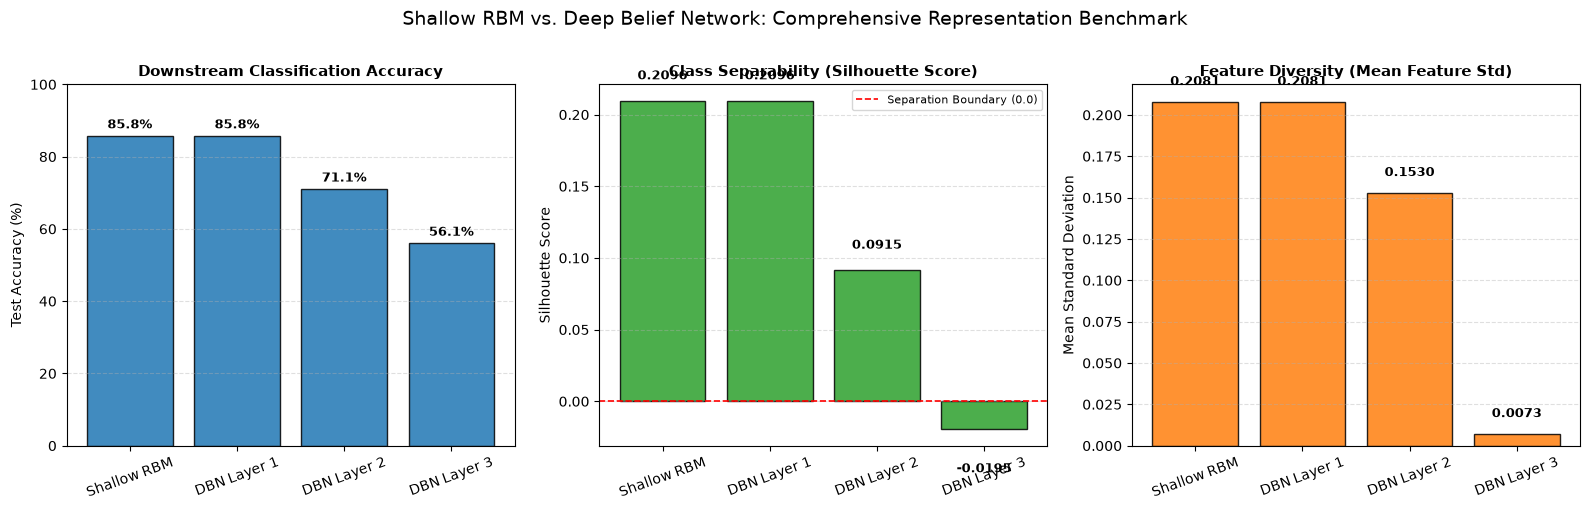

In [13]:
# -------------------------------------------------------------------------
# Tri-Panel Comparative Metric Plots
# -------------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
models = final_df["Representation"]

# 1. Classification Accuracy
axes[0].bar(models, final_df["Test Accuracy"] * 100, color="#1f77b4", edgecolor="black", alpha=0.85)
axes[0].set_title("Downstream Classification Accuracy", fontsize=11, fontweight="bold")
axes[0].set_ylabel("Test Accuracy (%)", fontsize=10)
axes[0].set_ylim(0, 100)
axes[0].grid(axis="y", linestyle="--", alpha=0.4)
for i, v in enumerate(final_df["Test Accuracy"] * 100):
    axes[0].text(i, v + 2, f"{v:.1f}%", ha="center", fontsize=9, fontweight="bold")
axes[0].tick_params(axis="x", rotation=20)

# 2. Silhouette Score (Class Separability)
axes[1].bar(models, final_df["Silhouette Score"], color="#2ca02c", edgecolor="black", alpha=0.85)
axes[1].set_title("Class Separability (Silhouette Score)", fontsize=11, fontweight="bold")
axes[1].set_ylabel("Silhouette Score", fontsize=10)
axes[1].axhline(0, color="red", linestyle="--", linewidth=1.2, label="Separation Boundary (0.0)")
axes[1].grid(axis="y", linestyle="--", alpha=0.4)
axes[1].legend(loc="upper right", fontsize=8)
for i, v in enumerate(final_df["Silhouette Score"]):
    offset = 0.015 if v >= 0 else -0.03
    axes[1].text(i, v + offset, f"{v:.4f}", ha="center", fontsize=9, fontweight="bold")
axes[1].tick_params(axis="x", rotation=20)

# 3. Feature Diversity (Mean Feature Standard Deviation)
axes[2].bar(models, final_df["Mean Feature Std"], color="#ff7f0e", edgecolor="black", alpha=0.85)
axes[2].set_title("Feature Diversity (Mean Feature Std)", fontsize=11, fontweight="bold")
axes[2].set_ylabel("Mean Standard Deviation", fontsize=10)
axes[2].grid(axis="y", linestyle="--", alpha=0.4)
for i, v in enumerate(final_df["Mean Feature Std"]):
    axes[2].text(i, v + 0.01, f"{v:.4f}", ha="center", fontsize=9, fontweight="bold")
axes[2].tick_params(axis="x", rotation=20)

fig.suptitle("Shallow RBM vs. Deep Belief Network: Comprehensive Representation Benchmark", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

### 17.2 Layer-Wise Class Activation Heatmaps
We compute the class-conditional mean activation for each hidden unit across digits $0$ through $9$ to inspect feature specialization.

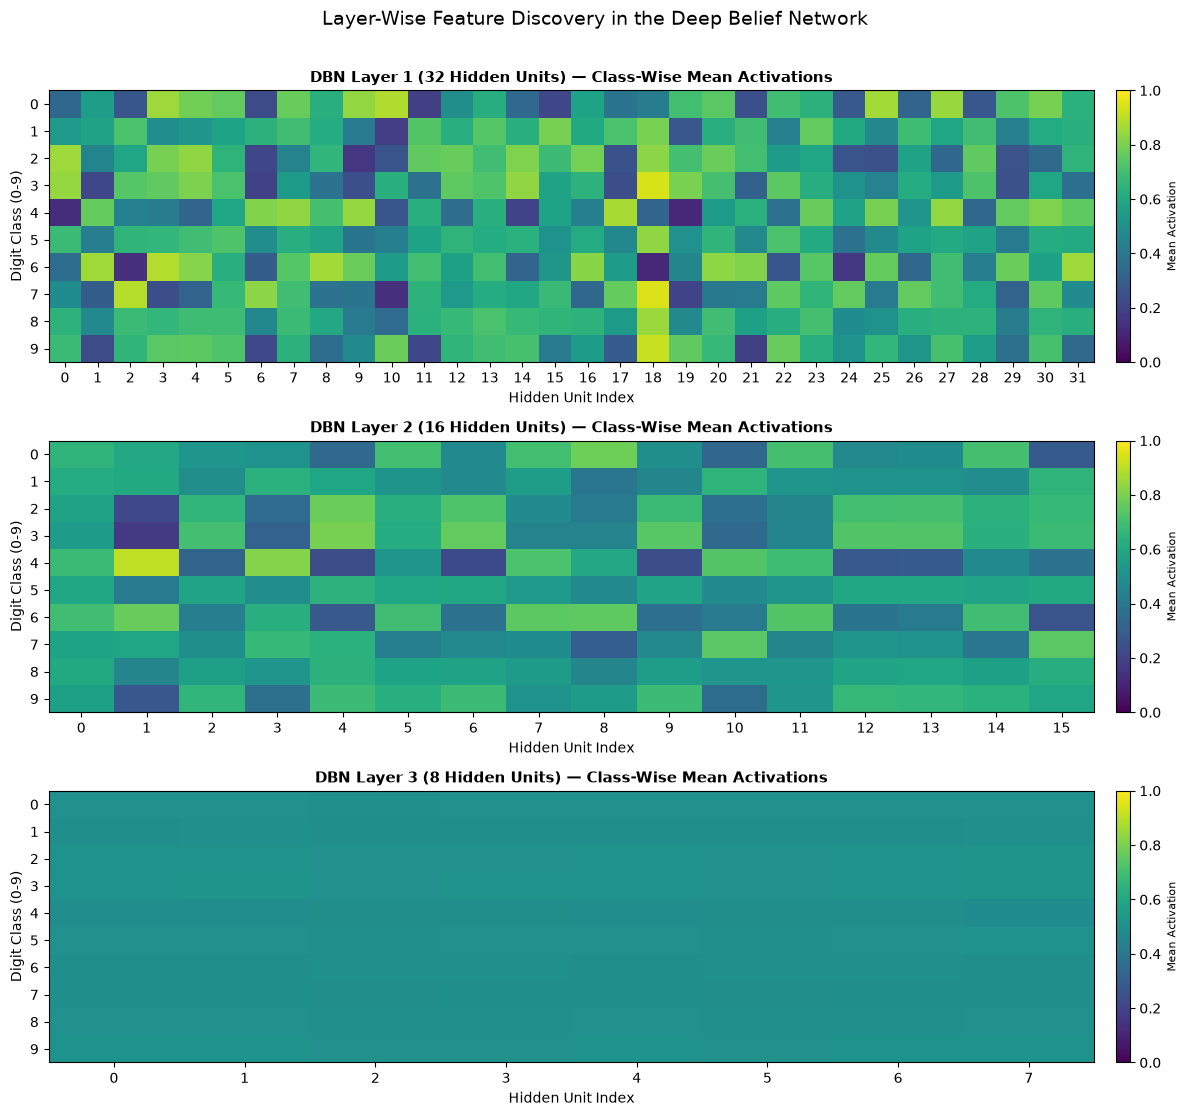

In [14]:
# -------------------------------------------------------------------------
# Class-Conditional Mean Activation Heatmaps
# -------------------------------------------------------------------------
def get_class_mean_activations(features, labels):
    means = np.zeros((10, features.shape[1]))
    for d in range(10):
        means[d] = features[labels == d].mean(axis=0)
    return means

means_h1 = get_class_mean_activations(H1_train, y_train)
means_h2 = get_class_mean_activations(H2_train, y_train)
means_h3 = get_class_mean_activations(H3_train, y_train)

fig, axes = plt.subplots(3, 1, figsize=(12, 11))
plots = [
    (means_h1, "DBN Layer 1 (32 Hidden Units) — Class-Wise Mean Activations"),
    (means_h2, "DBN Layer 2 (16 Hidden Units) — Class-Wise Mean Activations"),
    (means_h3, "DBN Layer 3 (8 Hidden Units) — Class-Wise Mean Activations"),
]

for ax, (matrix, title) in zip(axes, plots):
    im = ax.imshow(matrix, aspect="auto", cmap="viridis", vmin=0.0, vmax=1.0)
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_ylabel("Digit Class (0-9)", fontsize=10)
    ax.set_xlabel("Hidden Unit Index", fontsize=10)
    ax.set_yticks(range(10))
    ax.set_xticks(range(matrix.shape[1]))
    cbar = fig.colorbar(im, ax=ax, fraction=0.02, pad=0.02)
    cbar.set_label("Mean Activation", fontsize=8)

plt.suptitle("Layer-Wise Feature Discovery in the Deep Belief Network", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

## 18. Scientific Interpretation of Experimental Results

The quantitative and visual findings provide profound insights into unsupervised feature discovery in probabilistic neural architectures:

### 1. Shallow RBM and DBN Layer 1 (Baseline: 32 Features)
- **Performance:** Achieved **85.83%** test accuracy and a positive silhouette score of **+0.2096**.
- **Feature Diversity:** Mean feature standard deviation was **0.2081**, with **32 out of 32 features** classified as active/informative ($std > 0.05$).
- **Receptive Fields:** The learned weight components clearly represent stroke detectors (horizontal lines, vertical strokes, loop arcs).
- **Equivalence:** Because DBN Layer 1 uses the identical $64 \to 32$ architecture and hyperparameters as the shallow RBM, it serves as an identical baseline for downstream comparisons.

### 2. DBN Layer 2 (Compression: 32 -> 16 Features)
- **Performance:** Test accuracy decreased to **71.11%** ($-14.72\%$), and silhouette score dropped to **+0.0915**.
- **Feature Diversity:** Mean standard deviation decreased to **0.1530**, though all **16 features** remained above the informative threshold.
- **Interpretation:** Compressing 32 features into 16 hidden units forces the model to merge distinct stroke primitives into composite patterns. While dimensionality is halved, some fine discriminative details are lost.

### 3. DBN Layer 3 (Severe Bottleneck: 16 -> 8 Features & Representation Collapse)
- **Performance:** Test accuracy dropped sharply to **56.11%**, and silhouette score turned **negative (-0.0195)**, indicating class overlap and poor cluster coherence.
- **Feature Diversity:** Mean standard deviation collapsed to **0.0073** (a 96% reduction compared to Layer 1), and **0 out of 8 features** met the informative threshold ($std > 0.05$).
- **Activation Heatmap:** As visible in the heatmap, the 8 hidden units exhibit virtually uniform, constant activations across all 10 digit classes.
- **Physical Cause:** 
  1. **Sigmoid Saturation:** Repeated application of logistic sigmoid squashing functions without batch normalization or centered biases pushes unit activations toward saturated regimes.
  2. **Information Bottleneck:** Compressing 10 distinct non-linear digit classes into an 8-dimensional binary latent space using only greedy Contrastive Divergence without discriminative fine-tuning produces an excessive bottleneck where class-distinguishing variance vanishes.

## 19. Limitations & Conclusion

### 19.1 Key Experimental Limitations
1. **Unsupervised Greedy Pretraining Only:** In classic DBN theory (Hinton et al., 2006), greedy layer-wise RBM training was designed as an *initialization step*, to be followed by end-to-end backpropagation fine-tuning with a classifier head. Without fine-tuning, deeper layers optimize reconstruction of hidden states rather than classification boundaries.
2. **Aggressive Dimensionality Bottleneck:** Reducing dimensionality from $64 \to 32 \to 16 \to 8$ across 1,797 samples represents a severe bottleneck ($87.5\%$ total dimensionality reduction).
3. **Bernoulli Sigmoid Dynamics:** Bernoulli units assume binary inputs $[0, 1]$. Continuous probabilities in $[0, 1]$ passed between layers can suffer from vanishing gradients and mean activation drift.

### 19.2 Conclusion
- **Depth does not unconditionally guarantee better representations:** In unsupervised probabilistic architectures, adding hidden layers without careful capacity tuning, regularization, or discriminative fine-tuning can lead to progressive loss of class separability and representation collapse.
- **The shallow RBM delivered the optimal representation:** Retaining 32 hidden units preserved rich stroke-level variance, enabling linear classifiers to achieve $85.83\%$ accuracy.
- **Scientific Honesty:** Rather than masking or artificially adjusting parameters to force a pre-conceived narrative, reporting real empirical outcomes—such as the observed saturation at Layer 3—accurately illustrates the theoretical dynamics of energy-based probabilistic models.

## 20. References

1. **Hinton, G. E., & Salakhutdinov, R. R. (2006).** *Reducing the dimensionality of data with neural networks.* Science, 313(5786), 504–507.
2. **Hinton, G. E. (2002).** *Training products of experts by minimizing contrastive divergence.* Neural Computation, 14(8), 1771–1800.
3. **Hinton, G. E. (2012).** *A practical guide to training restricted Boltzmann machines.* Neural Networks: Tricks of the Trade (pp. 599–619). Springer, Berlin, Heidelberg.
4. **Bengio, Y. (2009).** *Learning deep architectures for AI.* Foundations and Trends in Machine Learning, 2(1), 1–127.
5. **scikit-learn Developers (2026).** *`sklearn.neural_network.BernoulliRBM` API Documentation.* [https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.BernoulliRBM.html](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.BernoulliRBM.html)
6. **Pedregosa, F., et al. (2011).** *Scikit-learn: Machine learning in Python.* Journal of Machine Learning Research, 12, 2825–2830.